# Guide Pratique Pandas : De la Création à l'Extraction
## Maîtriser l'Analyse de Données Tabulaires en 3 Étapes Fondamentales
### (1. Création • 2. Manipulation • 3. Extraction)

---

### Objectifs d'apprentissage :
Ce notebook constitue un guide complet et progressif pour la manipulation de données en **Python** avec la bibliothèque **Pandas**. Il s'articule autour de 3 piliers essentiels du cycle de traitement des données tabulaires :
1. **Création & Initialisation (Creation)** : Construire et charger des `Series` et des `DataFrames` depuis la mémoire (listes, dictionnaires, tableaux NumPy) et des sources externes (CSV, JSON, flux de chaînes).
2. **Manipulation & Traitement (Manipulation)** : Inspecter la structure, nettoyer les données manquantes, appliquer des transformations vectorisées, restructurer (`groupby`, `merge`, `concat`).
3. **Extraction & Exportation (Extraction)** : Filtrer précisément (`loc`, `iloc`, `.query()`), extraire des sous-ensembles ciblés, construire des tableaux de synthèse et sérialiser les résultats dans des formats de production (`CSV`, `JSON`, `Excel`, `Parquet`).

---

## 0. Configuration de l'Environnement et Importations

Nous importons `pandas` ainsi que `numpy` pour les calculs numériques et la gestion des valeurs nulles (`np.nan`), et `matplotlib`/`seaborn` pour illustrer graphiquement nos analyses.

In [1]:
# Importation des bibliothèques fondamentales
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration de l'affichage Pandas
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
pd.set_option('display.precision', 2)

# Configuration graphique
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"Version de Pandas installée : {pd.__version__}")
print(f"Version de NumPy installée  : {np.__version__}")

Version de Pandas installée : 2.3.3
Version de NumPy installée  : 2.3.4


---

# ÉTAPE 1 : CRÉATION & INITIALISATION DES DONNÉES (CREATION)

Pandas repose sur deux structures de données principales :
- **`pd.Series`** : Tableau unidimensionnel étiqueté capable de stocker tout type de données.
- **`pd.DataFrame`** : Structure bidimensionnelle (lignes et colonnes) équivalente à une table SQL ou une feuille de calcul Excel.

---

### 1.1 Création de `pd.Series`

In [2]:
# 1.1.1 Création d'une Série à partir d'une simple liste avec index par défaut (0, 1, 2, ...)
notes = pd.Series([14.5, 18.0, 12.0, 16.5], name="Notes_DS")
print("--- Série avec index entier automatique ---")
print(notes)

--- Série avec index entier automatique ---
0    14.5
1    18.0
2    12.0
3    16.5
Name: Notes_DS, dtype: float64


In [3]:
# 1.1.2 Création d'une Série avec index nominatifs personnalisés
etudiants = ["Amine", "Sarah", "Youssef", "Khadija"]
notes_etudiants = pd.Series([14.5, 18.0, 12.0, 16.5], index=etudiants, name="Note_Python")
print("--- Série avec index personnalisé (Noms) ---")
print(notes_etudiants)

--- Série avec index personnalisé (Noms) ---
Amine      14.5
Sarah      18.0
Youssef    12.0
Khadija    16.5
Name: Note_Python, dtype: float64


In [4]:
# 1.1.3 Création directe depuis un dictionnaire Python (les clés deviennent l'index)
capitales = {
    "Tunisie": "Tunis",
    "France": "Paris",
    "Canada": "Ottawa",
    "Japon": "Tokyo"
}
serie_capitales = pd.Series(capitales, name="Capitale")
print("--- Série générée depuis un dictionnaire ---")
print(serie_capitales)

--- Série générée depuis un dictionnaire ---
Tunisie     Tunis
France      Paris
Canada     Ottawa
Japon       Tokyo
Name: Capitale, dtype: object


---

### 1.2 Création de `pd.DataFrame` en Mémoire

In [5]:
# 1.2.1 Création depuis un dictionnaire de listes (approche la plus fréquente)
donnees_magasin = {
    "ID_Produit": [101, 102, 103, 104, 105],
    "Nom": ["Clavier Mécanique", "Souris Sans Fil", "Écran 27 pouces", "Casque Audio", "Tapis XL"],
    "Categorie": ["Périphérique", "Périphérique", "Affichage", "Audio", "Accessoire"],
    "Prix_Unitaire": [85.0, 35.5, 240.0, 110.0, 20.0],
    "Stock": [15, 30, 8, 22, 50]
}

df_produits = pd.DataFrame(donnees_magasin)
print("--- DataFrame créé depuis un dictionnaire de listes ---")
df_produits

--- DataFrame créé depuis un dictionnaire de listes ---


,ID_Produit,Nom,Categorie,Prix_Unitaire,Stock
0,101,Clavier Mécanique,Périphérique,85.0,15
1,102,Souris Sans Fil,Périphérique,35.5,30
2,103,Écran 27 pouces,Affichage,240.0,8
3,104,Casque Audio,Audio,110.0,22
4,105,Tapis XL,Accessoire,20.0,50


In [6]:
# 1.2.2 Création depuis une liste de dictionnaires (format standard retourné par les API REST / MongoDB)
ventes_brutes = [
    {"Date": "2026-10-01", "Client": "Société A", "Total": 1250.0, "Statut": "Livré"},
    {"Date": "2026-10-02", "Client": "Société B", "Total": 430.5, "Statut": "En attente"},
    {"Date": "2026-10-03", "Client": "Société C", "Total": 2900.0, "Statut": "Livré"},
    {"Date": "2026-10-04", "Client": "Société A", "Total": 850.0, "Statut": "Annulé"}
]

df_ventes = pd.DataFrame(ventes_brutes)
print("--- DataFrame créé depuis une liste de dictionnaires (JSON format) ---")
df_ventes

--- DataFrame créé depuis une liste de dictionnaires (JSON format) ---


,Date,Client,Total,Statut
0,2026-10-01,Société A,1250.0,Livré
1,2026-10-02,Société B,430.5,En attente
2,2026-10-03,Société C,2900.0,Livré
3,2026-10-04,Société A,850.0,Annulé


In [7]:
# 1.2.3 Création depuis une matrice 2D NumPy avec noms de colonnes et index explicites
matrice_numpy = np.random.normal(loc=20, scale=3, size=(5, 3))
df_capteurs = pd.DataFrame(
    matrice_numpy,
    columns=["Capteur_Temperature", "Capteur_Pression", "Capteur_Humidite"],
    index=[f"Station_{i}" for i in range(1, 6)]
)
print("--- DataFrame généré depuis une matrice NumPy aléatoire ---")
df_capteurs

--- DataFrame généré depuis une matrice NumPy aléatoire ---


,Capteur_Temperature,Capteur_Pression,Capteur_Humidite
Station_1,19.18,22.74,15.99
Station_2,24.14,18.00,21.07
Station_3,25.98,22.75,21.14
Station_4,22.16,20.75,17.45
Station_5,27.00,13.62,19.27


---

### 1.3 Ingestion depuis des Fichiers et Flux Externes (`read_csv`, `read_json`, `StringIO`)

Dans la pratique réelle, les données proviennent de fichiers stockés sur disque ou de flux web. Simulons un fichier CSV avec des types hétérogènes et des valeurs manquantes.

In [8]:
# Simulation d'un fichier CSV en mémoire grâce à io.StringIO
flux_csv = io.StringIO("""employe_id,nom,departement,date_embauche,salaire,performance_score
E01,Mohamed Ben Ali,Data Science,2021-03-15,4500,92
E02,Sonia Trabelsi,Machine Learning,2020-07-01,5200,95
E03,Karim Mansour,Data Engineering,2022-01-10,,88
E04,Ines Jaziri,Data Science,2019-11-20,6100,
E05,Walid Gharbi,Marketing,2023-05-04,3200,74
E06,Aya Bouazizi,Data Engineering,2021-09-12,4800,91
E07,Nader Hammami,Machine Learning,2024-02-01,3900,82
""")

# Lecture avec typage automatique et parsing des dates
df_employes = pd.read_csv(
    flux_csv,
    parse_dates=["date_embauche"]
)

print("--- DataFrame lu depuis CSV (avec détection de dates et valeurs manquantes) ---")
df_employes

--- DataFrame lu depuis CSV (avec détection de dates et valeurs manquantes) ---


,employe_id,nom,departement,date_embauche,salaire,performance_score
0,E01,Mohamed Ben Ali,Data Science,2021-03-15,4500.0,92.0
1,E02,Sonia Trabelsi,Machine Learning,2020-07-01,5200.0,95.0
2,E03,Karim Mansour,Data Engineering,2022-01-10,NaN,88.0
3,E04,Ines Jaziri,Data Science,2019-11-20,6100.0,NaN
4,E05,Walid Gharbi,Marketing,2023-05-04,3200.0,74.0
5,E06,Aya Bouazizi,Data Engineering,2021-09-12,4800.0,91.0
6,E07,Nader Hammami,Machine Learning,2024-02-01,3900.0,82.0


---

# ÉTAPE 2 : MANIPULATION & TRAITEMENT DES DONNÉES (MANIPULATION)

Une fois les données créées ou chargées, l'étape de manipulation consiste à diagnostiquer, nettoyer, transformer, enrichir et combiner les tables pour les rendre exploitables.

---

### 2.1 Inspection et Diagnostic Qualité

In [9]:
# Aperçu structurel, dimensions et types de données
print("=== Forme du DataFrame (lignes, colonnes) ===")
print(df_employes.shape)

print("\n=== Informations détaillées (Types & Valeurs non-nulles) ===")
df_employes.info()

print("\n=== Résumé statistique des variables numériques ===")
print(df_employes.describe().T)

=== Forme du DataFrame (lignes, colonnes) ===
(7, 6)

=== Informations détaillées (Types & Valeurs non-nulles) ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   employe_id         7 non-null      object        
 1   nom                7 non-null      object        
 2   departement        7 non-null      object        
 3   date_embauche      7 non-null      datetime64[ns]
 4   salaire            6 non-null      float64       
 5   performance_score  6 non-null      float64       
dtypes: datetime64[ns](1), float64(2), object(3)
memory usage: 468.0+ bytes

=== Résumé statistique des variables numériques ===
                  count                           mean                  min                  25%                  50%                  75%                  max      std
date_embauche         7  2021-10-26 06:51:25.71

In [10]:
# Détection et comptage des valeurs nulles par colonne
valeurs_nulles = df_employes.isna().sum()
pourcentage_nulles = (df_employes.isna().mean() * 100)
diagnostic_nulls = pd.DataFrame({"Nombre_NaN": valeurs_nulles, "Pourcentage_%": pourcentage_nulles})
print("=== Diagnostic des valeurs manquantes (Missing Values) ===")
diagnostic_nulls

=== Diagnostic des valeurs manquantes (Missing Values) ===


,Nombre_NaN,Pourcentage_%
employe_id,0,0.00
nom,0,0.00
departement,0,0.00
date_embauche,0,0.00
salaire,1,14.29
performance_score,1,14.29


---

### 2.2 Nettoyage et Imputation des Données Manquantes

In [11]:
# Création d'une copie de travail pour préserver le DataFrame original
df_clean = df_employes.copy()

# Calcul des statistiques d'imputation
salaire_median = df_clean["salaire"].median()
score_moyen = df_clean["performance_score"].mean()

print(f"Imputation du salaire manquant par la médiane : {salaire_median:.2f} DT")
print(f"Imputation du score de performance par la moyenne : {score_moyen:.2f}")

# Application de l'imputation via .fillna()
df_clean["salaire"] = df_clean["salaire"].fillna(salaire_median)
df_clean["performance_score"] = df_clean["performance_score"].fillna(score_moyen)

# Vérification après nettoyage
print(f"Total des valeurs manquantes restantes : {df_clean.isna().sum().sum()}")
df_clean

Imputation du salaire manquant par la médiane : 4650.00 DT
Imputation du score de performance par la moyenne : 87.00
Total des valeurs manquantes restantes : 0


,employe_id,nom,departement,date_embauche,salaire,performance_score
0,E01,Mohamed Ben Ali,Data Science,2021-03-15,4500.0,92.0
1,E02,Sonia Trabelsi,Machine Learning,2020-07-01,5200.0,95.0
2,E03,Karim Mansour,Data Engineering,2022-01-10,4650.0,88.0
3,E04,Ines Jaziri,Data Science,2019-11-20,6100.0,87.0
4,E05,Walid Gharbi,Marketing,2023-05-04,3200.0,74.0
5,E06,Aya Bouazizi,Data Engineering,2021-09-12,4800.0,91.0
6,E07,Nader Hammami,Machine Learning,2024-02-01,3900.0,82.0


---

### 2.3 Ingénierie des Caractéristiques (Feature Engineering)

Ajout de nouvelles colonnes dérivées, calcul vectoriel et manipulation des dates et chaînes.

In [12]:
# Calcul de l'ancienneté en années par rapport à la date de référence (2026-10-20)
date_reference = pd.to_datetime("2026-10-20")
df_clean["anciennete_annees"] = ((date_reference - df_clean["date_embauche"]).dt.days / 365.25).round(1)

# Normalisation textuelle : Noms en majuscules et extraction du prénom
df_clean["nom_complet_maj"] = df_clean["nom"].str.upper()
df_clean["prenom"] = df_clean["nom"].str.split(" ").str[0]

# Calcul vectoriel : Prime annuelle estimée à 10% du salaire pour chaque tranche de score > 85
df_clean["prime_annuelle"] = np.where(df_clean["performance_score"] >= 90, df_clean["salaire"] * 1.5, df_clean["salaire"] * 0.5)

print("--- DataFrame enrichi avec de nouvelles variables (Feature Engineering) ---")
df_clean[["nom", "departement", "anciennete_annees", "salaire", "performance_score", "prime_annuelle"]]

--- DataFrame enrichi avec de nouvelles variables (Feature Engineering) ---


,nom,departement,anciennete_annees,salaire,performance_score,prime_annuelle
0,Mohamed Ben Ali,Data Science,5.6,4500.0,92.0,6750.0
1,Sonia Trabelsi,Machine Learning,6.3,5200.0,95.0,7800.0
2,Karim Mansour,Data Engineering,4.8,4650.0,88.0,2325.0
3,Ines Jaziri,Data Science,6.9,6100.0,87.0,3050.0
4,Walid Gharbi,Marketing,3.5,3200.0,74.0,1600.0
5,Aya Bouazizi,Data Engineering,5.1,4800.0,91.0,7200.0
6,Nader Hammami,Machine Learning,2.7,3900.0,82.0,1950.0


---

### 2.4 Application de Fonctions Personnalisées (`apply`, `map`)

In [13]:
# Définition d'une fonction métier de classification
def classifier_seniorite(annees):
    if annees < 2.5:
        return "Junior"
    elif annees < 5.0:
        return "Confirmé"
    else:
        return "Senior"

# Application de la fonction via .apply()
df_clean["niveau_seniorite"] = df_clean["anciennete_annees"].apply(classifier_seniorite)

# Affichage des effectifs par niveau
print("=== Répartition des niveaux de séniorité ===")
print(df_clean["niveau_seniorite"].value_counts())

=== Répartition des niveaux de séniorité ===
niveau_seniorite
Senior      4
Confirmé    3
Name: count, dtype: int64


---

### 2.5 Agrégation et Synthèse par Groupe (Le paradigme `Split-Apply-Combine`)

Le regroupement avec `groupby()` permet de segmenter le jeu de données selon une ou plusieurs variables catégorielles et d'appliquer des fonctions d'agrégation.

In [14]:
# Analyse comparative par département : Salaire moyen, Score max, Nombre d'employés
agregations = {
    "salaire": ["count", "mean", "median"],
    "performance_score": ["mean", "max"],
    "prime_annuelle": "sum"
}

synthese_dept = df_clean.groupby("departement").agg(agregations)
# Aplatir les colonnes MultiIndex pour faciliter la lecture
synthese_dept.columns = ['_'.join(col).strip() for col in synthese_dept.columns.values]
print("--- Synthèse statistique par Département ---")
synthese_dept.reset_index()

--- Synthèse statistique par Département ---


,departement,salaire_count,salaire_mean,salaire_median,performance_score_mean,performance_score_max,prime_annuelle_sum
0,Data Engineering,2,4725.0,4725.0,89.5,91.0,9525.0
1,Data Science,2,5300.0,5300.0,89.5,92.0,9800.0
2,Machine Learning,2,4550.0,4550.0,88.5,95.0,9750.0
3,Marketing,1,3200.0,3200.0,74.0,74.0,1600.0


---

### 2.6 Fusion et Combinaison de Tables (`merge` & `concat`)

Simulons une seconde table contenant les budgets alloués à chaque département pour réaliser une jointure relationnelle (`merge`).

In [15]:
# Table secondaire : Budgets par département
donnees_budgets = pd.DataFrame({
    "departement": ["Data Science", "Machine Learning", "Data Engineering", "Marketing", "Cybersecurite"],
    "budget_annuel_kdt": [250, 320, 280, 150, 200],
    "responsable": ["Dr. Slim", "Dr. Monia", "Ing. Firas", "Mme. Leila", "Ing. Tarek"]
})

# Fusion relationnelle de type gauche (Left Join)
df_fusion = pd.merge(df_clean, donnees_budgets, on="departement", how="left")
print("--- Résultat de la fusion relationnelle (Left Join) ---")
df_fusion[["nom", "departement", "salaire", "budget_annuel_kdt", "responsable"]]

--- Résultat de la fusion relationnelle (Left Join) ---


,nom,departement,salaire,budget_annuel_kdt,responsable
0,Mohamed Ben Ali,Data Science,4500.0,250,Dr. Slim
1,Sonia Trabelsi,Machine Learning,5200.0,320,Dr. Monia
2,Karim Mansour,Data Engineering,4650.0,280,Ing. Firas
3,Ines Jaziri,Data Science,6100.0,250,Dr. Slim
4,Walid Gharbi,Marketing,3200.0,150,Mme. Leila
5,Aya Bouazizi,Data Engineering,4800.0,280,Ing. Firas
6,Nader Hammami,Machine Learning,3900.0,320,Dr. Monia


---

# ÉTAPE 3 : EXTRACTION, REQUÊTAGE & EXPORTATION (EXTRACTION)

La troisième étape consiste à cibler des sous-ensembles spécifiques, à découper la table (`slicing`), à exécuter des requêtes conditionnelles complexes et à persister les résultats dans des formats de production.

---

### 3.1 Sélection Ciblée : `loc` (par étiquettes) vs `iloc` (par positions entières)

- **`df.loc[lignes, colonnes]`** : Sélection basée sur les étiquettes de l'index et les noms des colonnes.
- **`df.iloc[lignes, colonnes]`** : Sélection basée sur les indices entiers de position (0-indexed).

In [16]:
# 3.1.1 Utilisation de .iloc : Extraire les 3 premières lignes et les 4 premières colonnes
selection_iloc = df_clean.iloc[0:3, 0:4]
print("--- Extraction avec .iloc (positions 0:3, 0:4) ---")
selection_iloc

--- Extraction avec .iloc (positions 0:3, 0:4) ---


,employe_id,nom,departement,date_embauche
0,E01,Mohamed Ben Ali,Data Science,2021-03-15
1,E02,Sonia Trabelsi,Machine Learning,2020-07-01
2,E03,Karim Mansour,Data Engineering,2022-01-10


In [17]:
# 3.1.2 Utilisation de .loc : Filtrer les employés du département Data Science et extraire nom + salaire
selection_loc = df_clean.loc[df_clean["departement"] == "Data Science", ["nom", "salaire", "performance_score"]]
print("--- Extraction avec .loc (Condition + Colonnes spécifiques) ---")
selection_loc

--- Extraction avec .loc (Condition + Colonnes spécifiques) ---


,nom,salaire,performance_score
0,Mohamed Ben Ali,4500.0,92.0
3,Ines Jaziri,6100.0,87.0


---

### 3.2 Filtrage Booléen et Requêtes Expressives (`.query()`)

In [18]:
# 3.2.1 Filtrage classique par masque booléen multi-critères (& pour ET, | pour OU, ~ pour NON)
critere = (df_clean["salaire"] >= 4500) & (df_clean["performance_score"] > 90)
employes_haut_potentiel = df_clean[critere]
print(f"--- Employés à haut potentiel (Salaire >= 4500 & Score > 90) : {len(employes_haut_potentiel)} trouvés ---")
employes_haut_potentiel[["nom", "departement", "salaire", "performance_score"]]

--- Employés à haut potentiel (Salaire >= 4500 & Score > 90) : 3 trouvés ---


,nom,departement,salaire,performance_score
0,Mohamed Ben Ali,Data Science,4500.0,92.0
1,Sonia Trabelsi,Machine Learning,5200.0,95.0
5,Aya Bouazizi,Data Engineering,4800.0,91.0


In [19]:
# 3.2.2 Requête dynamique expressive avec .query()
# Syntaxe très élégante, optimisée et lisible
seuil_salaire = 4000
resultat_query = df_clean.query("salaire > @seuil_salaire and departement in ['Data Science', 'Machine Learning']")
print(f"--- Extraction via df.query() (salaire > {seuil_salaire} en DS ou ML) ---")
resultat_query[["nom", "departement", "salaire", "niveau_seniorite"]]

--- Extraction via df.query() (salaire > 4000 en DS ou ML) ---


,nom,departement,salaire,niveau_seniorite
0,Mohamed Ben Ali,Data Science,4500.0,Senior
1,Sonia Trabelsi,Machine Learning,5200.0,Senior
3,Ines Jaziri,Data Science,6100.0,Senior


---

### 3.3 Extractions Statistiques Avancées : Tops, Valeurs Uniques et Tableaux Croisés

In [20]:
# 3.3.1 Extraire les Top 3 salaires les plus élevés
top_3_salaires = df_clean.nlargest(3, "salaire")
print("--- Top 3 des salaires les plus élevés ---")
top_3_salaires[["nom", "departement", "salaire", "anciennete_annees"]]

--- Top 3 des salaires les plus élevés ---


,nom,departement,salaire,anciennete_annees
3,Ines Jaziri,Data Science,6100.0,6.9
1,Sonia Trabelsi,Machine Learning,5200.0,6.3
5,Aya Bouazizi,Data Engineering,4800.0,5.1


In [21]:
# 3.3.2 Extraction des valeurs uniques et du cardinal
print("Départements uniques représentés :", df_clean["departement"].unique())
print("Nombre de départements distincts :", df_clean["departement"].nunique())

Départements uniques représentés : ['Data Science' 'Machine Learning' 'Data Engineering' 'Marketing']
Nombre de départements distincts : 4


In [22]:
# 3.3.3 Tableau croisé dynamique (Pivot Table) pour synthèse matricielle
tableau_pivot = df_clean.pivot_table(
    index="departement",
    columns="niveau_seniorite",
    values="salaire",
    aggfunc="mean",
    fill_value=0
)
print("--- Tableau croisé dynamique : Salaire moyen par Département et Niveau ---")
tableau_pivot

--- Tableau croisé dynamique : Salaire moyen par Département et Niveau ---


niveau_seniorite,Confirmé,Senior
departement,,
Data Engineering,4650.0,4800.0
Data Science,0.0,5300.0
Machine Learning,3900.0,5200.0
Marketing,3200.0,0.0


---

### 3.4 Sérialisation et Exportation des Résultats

Pandas permet d'exporter n'importe quel sous-ensemble vers les formats standards de stockage et d'échange de données.

In [23]:
# Exportation vers CSV (sans l'index numérique)
df_clean.to_csv("export_employes_nettoye.csv", index=False, encoding="utf-8")

# Exportation du tableau de synthèse vers JSON (format records)
synthese_dept.to_json("export_synthese_departements.json", orient="records", indent=2)

# Exportation vers Parquet (format columnaire haute performance pour le Big Data)
try:
    df_clean.to_parquet("export_employes.parquet", index=False)
    parquet_ok = True
except Exception as e:
    parquet_ok = False
    print("Moteur parquet optionnel non présent :", e)

print("Exportations terminées avec succès :")
print(" ✓ export_employes_nettoye.csv généré")
print(" ✓ export_synthese_departements.json généré")
if parquet_ok:
    print(" ✓ export_employes.parquet généré")

Moteur parquet optionnel non présent : Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - Missing optional dependency 'pyarrow'. pyarrow is required for parquet support. Use pip or conda to install pyarrow.
 - Missing optional dependency 'fastparquet'. fastparquet is required for parquet support. Use pip or conda to install fastparquet.
Exportations terminées avec succès :
 ✓ export_employes_nettoye.csv généré
 ✓ export_synthese_departements.json généré


---

## 4. Visualisation Graphique des Résultats Extraits

Pour clore le cycle analytique, nous produisons une planche de bord synthétique résumant les données manipulées et extraites.

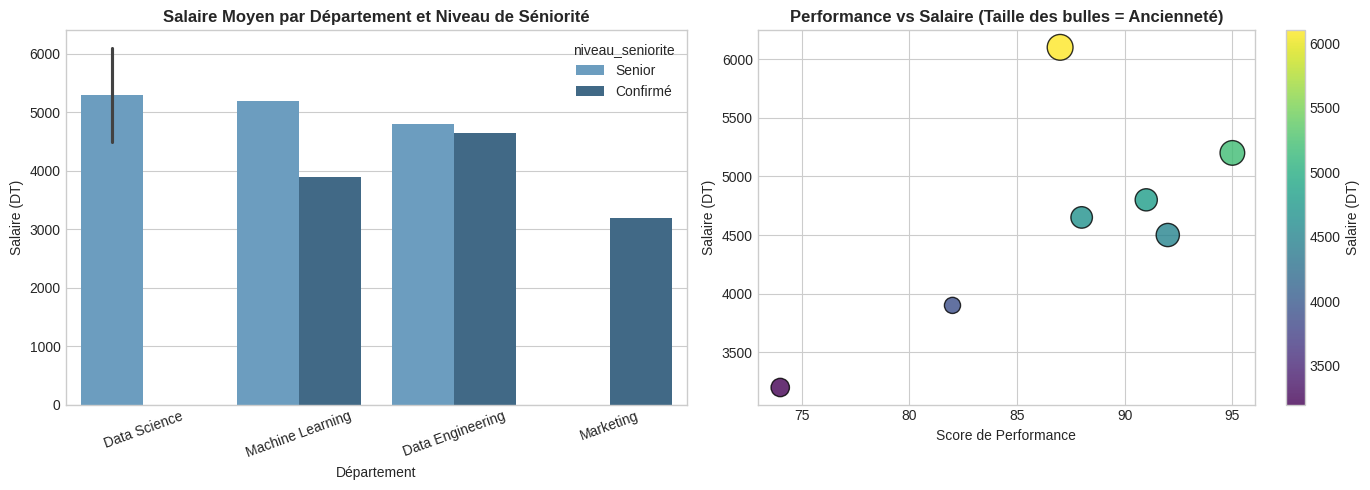

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Distribution des salaires par département
sns.barplot(
    data=df_clean,
    x="departement",
    y="salaire",
    hue="niveau_seniorite",
    palette="Blues_d",
    ax=axes[0]
)
axes[0].set_title("Salaire Moyen par Département et Niveau de Séniorité", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Département")
axes[0].set_ylabel("Salaire (DT)")
axes[0].tick_params(axis='x', rotation=20)

# Graphique 2 : Relation Performance vs Salaire avec taille proportionnelle à l'ancienneté
scatter = axes[1].scatter(
    df_clean["performance_score"],
    df_clean["salaire"],
    s=df_clean["anciennete_annees"] * 50,
    c=df_clean["salaire"],
    cmap="viridis",
    alpha=0.8,
    edgecolors="black"
)
axes[1].set_title("Performance vs Salaire (Taille des bulles = Ancienneté)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Score de Performance")
axes[1].set_ylabel("Salaire (DT)")
fig.colorbar(scatter, ax=axes[1], label="Salaire (DT)")

plt.tight_layout()
plt.show()

---

## 5. Résumé et Bonnes Pratiques Méthodologiques

| Phase | Outils Clés Pandas | Objectif & Règle d'or |
| :--- | :--- | :--- |
| **1. Création** | `pd.Series()`, `pd.DataFrame()`, `pd.read_csv()`, `pd.read_json()` | Définir rigoureusement les types (`dtypes`) et parser les dates dès l'ingestion. |
| **2. Manipulation** | `fillna()`, `dropna()`, `assign()`, `.str`, `groupby()`, `merge()` | Éviter les boucles Python `for` ; privilégier les opérations vectorisées et Split-Apply-Combine. |
| **3. Extraction** | `.loc[]`, `.iloc[]`, `.query()`, `.nlargest()`, `.to_csv()`, `.to_parquet()` | Utiliser `.loc` pour la précision sémantique, `.query()` pour la lisibilité et `index=False` lors de l'export. |